# Roman configurations

In [ ]:
import numpy as np
import os
import matplotlib.pyplot as plt
from glob import glob

import slsim
from slsim.Lenses.lens_pop import LensPop
from slsim.Pipelines.roman_speclite import configure_roman_filters
from slsim.Pipelines.roman_speclite import filter_names
import speclite
from astropy.cosmology import FlatLambdaCDM
from astropy.units import Quantity
import slsim.Sources as sources
import slsim.Deflectors as deflectors
import slsim.Pipelines as pipelines
import corner
from slsim.ImageSimulation.image_simulation import point_source_coordinate_properties
from slsim.Plots.plot_functions import create_image_montage_from_image_list
from slsim.ImageSimulation.roman_image_simulation import lens_image_roman

# Set STPSF_PATH in the environment when using a custom STPSF data directory.

%matplotlib inline

## Supernovae population for the Roman survey
In this notebook, we simulate a population of lensed supernovae for the Roman survey and images of randomly selected systems. Our workflow follows these steps:

1. Simulate a lensed supernova population
2. Choose a lens at random
3. Set the observation time and image configuration
4. Simulate the selected lens image
5. Visualize the result

To reuse precomputed kernels, we set `SLSIM_ROMAN_PSF_DIRECTORY` to a local copy of the [`cached_webb_psf` directory](https://github.com/LSST-strong-lensing/data_public/tree/main/webbpsf/cached_webb_psf). The collection provides kernels for F062, F106, F129, and F184.

## Set Roman configurations

In [2]:
from mejiro.instruments.roman import Roman

Roman.load_speclite_filters()

In [3]:
# Import default Roman Space Telescope configuration
skypy_config = 'roman-like.yml'

# # # generate Roman filters
# configure_roman_filters()

# # import filter bands and make them recogniable in speclite
# roman_filters = filter_names()
# # filters are ['Roman-F062', 'Roman-F087', 'Roman-F106', 'Roman-F129', 'Roman-F158', 'Roman-F184', 'Roman-F146', 'Roman-F213']

# speclite.filters.load_filters(
#     roman_filters[0],
#     roman_filters[1],
#     roman_filters[2],
#     roman_filters[3],
#     roman_filters[4],
#     roman_filters[5],
#     roman_filters[6],
#     roman_filters[7],
# )

## Simulate lensed supernovae population

In [ ]:
# define a cosmology
cosmo = FlatLambdaCDM(H0=70, Om0=0.3)

# # define a sky area
# deflector_sky_area = Quantity(value=5, unit="deg2")
# source_sky_area = Quantity(value=10, unit="deg2")
# host_sky_area = Quantity(value=2, unit="deg2")
# sky_area = Quantity(value=1000, unit="deg2")

# define a sky area
deflector_sky_area = Quantity(value=.05, unit="deg2")
source_sky_area = Quantity(value=.10, unit="deg2")
host_sky_area = Quantity(value=.02, unit="deg2")
sky_area = Quantity(value=100, unit="deg2")


# define limits in the intrinsic deflector and source population (in addition to the skypy config file)
kwargs_deflector_cut = {"band": "F062", "band_max": 28, "z_min": 0.01, "z_max": 2.5}
kwargs_source_cut = {"z_min": 0.01, "z_max": 5}

time_range = np.linspace(-50, 500, 550)
# Optional path to the externally downloaded SALT3.NIR_WAVEEXT model files.
modeldir = os.environ.get("SLSIM_SN_MODEL_DIR")

In [5]:
# generate galaxy population using skypy pipeline.
galaxy_simulation_pipeline = pipelines.SkyPyPipeline(
    skypy_config=skypy_config, sky_area=deflector_sky_area, filters=None, cosmo=cosmo
)

In [6]:
# generate galaxy population using skypy pipeline for host galaxies. These galaxies will
#  be used as host galaxy candidates.
galaxy_simulation_pipeline_host = pipelines.SkyPyPipeline(
    skypy_config=skypy_config, sky_area=host_sky_area, filters=None, cosmo=cosmo
)

In [7]:
# Initiate deflector population class
lens_galaxies = deflectors.EllipticalLensGalaxies(
    galaxy_list=galaxy_simulation_pipeline.red_galaxies,
    kwargs_cut=kwargs_deflector_cut,
    kwargs_mass2light={},
    cosmo=cosmo,
    sky_area=deflector_sky_area,
)

<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Deflectors/DeflectorPopulation/elliptical_lens_galaxies.py:48: UserWarning: Angular size is converted to arcsec because provided input_catalog_type is skypy. If this is not correct, please refer to the documentation of the class you are using
  galaxy_list = param_util.catalog_with_angular_size_in_arcsec(


In [8]:
# generate supernovae population
supernovae_catalog = sources.SupernovaeCatalog.SupernovaeCatalog(
    sn_type="Ia",
    band_list=["F184", "F129", "F062"],
    lightcurve_time=time_range,
    absolute_mag_band="bessellb",
    absolute_mag=None,
    mag_zpsys="ab",
    cosmo=cosmo,
    skypy_config=skypy_config,
    sky_area=source_sky_area,
    host_galaxy_candidate=galaxy_simulation_pipeline_host.blue_galaxies,
)
supernovae_data = supernovae_catalog.supernovae_catalog(
    host_galaxy=True, lightcurve=False
)

<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Sources/Supernovae/supernovae_lightcone.py:28: FutureWarning: Passing 'z' as keyword is deprecated since version 7.0 and will stop working in a future release. Pass it positionally to suppress this warning.
  sne_rate = SNIaRate(self._cosmo, self._input_redshifts[-1])
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Sources/Supernovae/supernovae_pop.py:95: IntegrationWarning: The maximum number of subdivisions (50) has been achieved.
  If increasing the limit yields no improvement it is advised to analyze 
  the integrand in order to determine the difficulties.  If the position of a 
  local difficulty can be determined (singularity, discontinuity) one will 
  probably gain from splitting up the interval and calling the integrator 
  on the subranges.  Perhaps a special-purpose integrator should be used.
  numerator = integrate.quad(
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Sources/Supernovae/superno

<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Sources/Supernovae/supernovae_pop.py:95: IntegrationWarning: The integral is probably divergent, or slowly convergent.
  numerator = integrate.quad(


In [ ]:
kwargs_sn = {
    "variability_model": "light_curve",
    "kwargs_variability": ["supernovae_lightcurve", "F184", "F129", "F062"],
    "sn_type": "Ia",
    "sn_absolute_mag_band": "bessellb",
    "sn_absolute_zpsys": "ab",
    "lightcurve_time": np.linspace(-50, 100, 150),
    "sn_modeldir": modeldir,
}

In [ ]:
source_SNIa = sources.PointPlusExtendedSources(
    point_plus_extended_sources_list=supernovae_data,
    cosmo=cosmo,
    sky_area=source_sky_area,
    kwargs_cut={},
    catalog_type="skypy",
    source_size=None,
    extended_source_type="single_sersic",
    point_source_type="supernova",
    point_source_kwargs=kwargs_sn,
)

In [11]:
#print(source_SNIa.__dict__)

In [12]:
# Initiate LensPop class
lens_pop = LensPop(
    deflector_population=lens_galaxies,
    source_population=source_SNIa,
    cosmo=cosmo,
    sky_area=sky_area,
)

In [13]:
# Draw lens population
#kwargs_lens_cut = {"min_image_separation": 0.5, "max_image_separation": 10}
kwargs_lens_cut = {"min_image_separation": 0.1, "max_image_separation": 10}

lens_population = lens_pop.draw_population(
    kwargs_lens_cuts=kwargs_lens_cut, speed_factor=10
)

<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file foun

<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file found, provide 0 instead.
  warnings.warn("No file found, provide 0 instead.")
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Util/ParamDistributions/kext_gext_distributions.py:126: UserWarning: No file foun

In [14]:
print("Number of lenses:", len(lens_population))

lens_samples = []
labels = [
    r"$\sigma_v$",
    r"$\log(M_{*})$",
    r"$\theta_E$",
    r"$z_{\rm l}$",
    r"$z_{\rm s}$",
    r"$m_{\rm source}$",
    r"$m_{\rm lens}$",
]

for gg_lens in lens_population:
    vel_disp = gg_lens.deflector_velocity_dispersion()
    m_star = gg_lens.deflector_stellar_mass()
    theta_e = gg_lens.einstein_radius[0]
    zl = gg_lens.deflector_redshift
    zs = gg_lens.source_redshift_list[0]
    source_mag = min(gg_lens.point_source_magnitude(band="F129", lensed=True)[0])
    #ps_mag_array = gg_lens.point_source_magnitude(band="F129", lensed=True)[0] ## this is an empty array
    # if ps_mag_array.size > 0:  # Check if array has elements
    #     source_mag = min(ps_mag_array)
    # else:
    #     source_mag = np.nan  # Use NaN for missing values
    deflector_mag = gg_lens.deflector_magnitude(band="F129")
    lens_samples.append(
        [vel_disp, np.log10(m_star), theta_e, zl, zs, source_mag, deflector_mag]
    )

Number of lenses: 96


<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Sources/Supernovae/supernova.py:114: UserWarning: bandpass 'f062' [4600, .., 7900] outside spectral range [9125.07, .., 91250.7]
Ignoring bandpass for now. Use extended wavelength SN models found here: https://github.com/LSST-strong-lensing/data_public/tree/main/sncosmo_sn_models
  warn(
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/sncosmo/models.py:189: RuntimeWarning: invalid value encountered in log10
  result[i] = -2.5 * np.log10(f / zpf)
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Sources/Supernovae/supernova.py:114: UserWarning: bandpass 'f062' [4600, .., 7900] outside spectral range [5326.78, .., 53267.8]
Ignoring bandpass for now. Use extended wavelength SN models found here: https://github.com/LSST-strong-lensing/data_public/tree/main/sncosmo_sn_models
  warn(
<PYTHON_ENV>s/mejiro-v3/lib/python3.13/site-packages/slsim/Sources/Supernovae/supernova.py:114: UserWarning: bandpass 'f062' [4600, .., 79

In [15]:
 gg_lens.point_source_magnitude?

Signature:
gg_lens.point_source_magnitude(
    band,
    lensed=False,
    time=None,
    microlensing=False,
    kwargs_microlensing=None,
)
Docstring:
Point source magnitude, either unlensed (single value) or lensed
(array) with macro-model magnifications. This function provided
magnitudes of all the sources.

# TODO: time-variability with micro-lensing

:param band: imaging band
:type band: string
:param lensed: if True, returns the lensed magnified magnitude
:type lensed: bool
:param time: time is an image observation time in units of days.
    If None, provides magnitude without variability.
:param microlensing: if using micro-lensing map to produce the
    lensed magnification
:type microlensing: bool
:param kwargs_microlensing: additional (optional) dictionary of
    settings required by micro-lensing calculation that do not
    depend on the Lens() class. It is of type:
    kwargs_microlensing = {"kwargs_MagnificationMap":
    kwargs_MagnificationMap, "point_source_morphology":

In [16]:
#print(gg_lens._point_source_magnification(0))
print(gg_lens.source(0).point_source_magnitude(band="F129"))

25.45590994712867


In [17]:
print(lens_samples[0])

[np.float64(305.2588365599634), np.float64(11.996551531662845), np.float64(0.9253217665430536), 1.5690062605355934, 3.5625359135608963, np.float64(27.704761401499347), np.float64(20.836459646639632)]


In [18]:
print(gg_lens.source, gg_lens.source)

<bound method Lens.source of <slsim.Lenses.lens.Lens object at 0x7f9fa507bd10>> <bound method Lens.source of <slsim.Lenses.lens.Lens object at 0x7f9fa507bd10>>


In [19]:
## clean the population. It removes supernovae with nan value for magnitude.
lens_samples = np.array(lens_samples)
cleaned_data = lens_samples[~np.isnan(lens_samples).any(axis=1)]

In [20]:
print(lens_samples[0])

[305.25883656  11.99655153   0.92532177   1.56900626   3.56253591
  27.7047614   20.83645965]


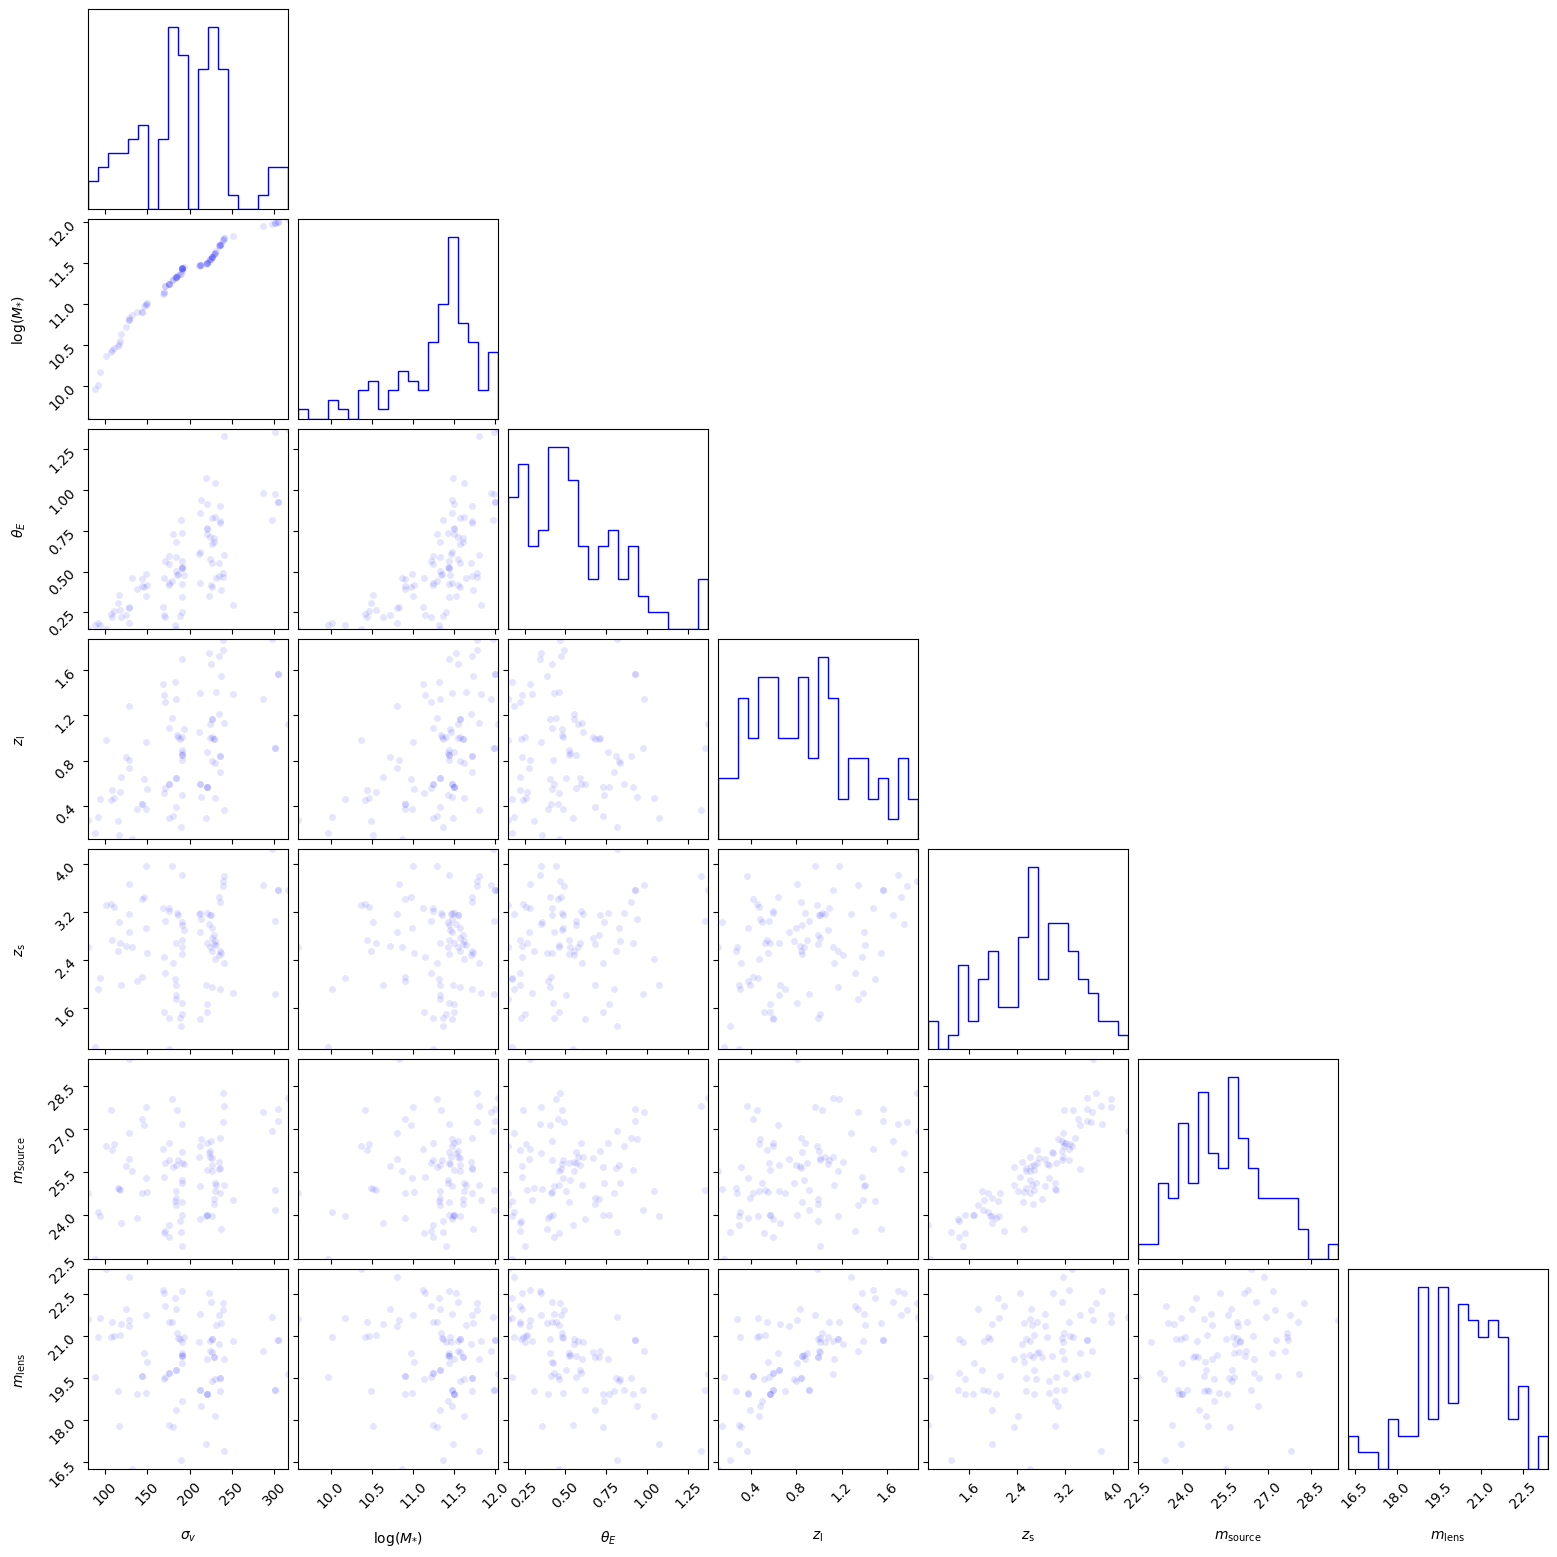

In [21]:
hist2dkwargs = {
    "plot_density": False,
    "plot_contours": False,
    "plot_datapoints": True,
    "color": "b",
    "data_kwargs": {"ms": 5},
}
corner.corner(np.array(cleaned_data), labels=labels, **hist2dkwargs) ##error clean_data is empty
plt.show()

In [22]:
print(np.array(cleaned_data))

[[3.05258837e+02 1.19965515e+01 9.25321767e-01 1.56900626e+00
  3.56253591e+00 2.77047614e+01 2.08364596e+01]
 [1.00815395e+02 1.03664683e+01 1.49016329e-01 9.84543450e-01
  3.31682888e+00 2.64251302e+01 2.33762374e+01]
 [3.05258837e+02 1.19965515e+01 9.25321767e-01 1.56900626e+00
  3.56253591e+00 2.72754045e+01 2.08364596e+01]
 [8.82632643e+01 9.97001028e+00 1.75504954e-01 1.68593116e-01
  9.46030668e-01 2.24884167e+01 1.95455579e+01]
 [1.90113690e+02 1.13647854e+01 8.12324151e-01 2.15846289e-01
  1.30176087e+00 2.34274127e+01 1.65699597e+01]
 [1.70260635e+02 1.12147888e+01 2.19370910e-01 1.31486199e+00
  2.18017861e+00 2.34771872e+01 2.20634696e+01]
 [2.51227780e+02 1.18304452e+01 2.92484048e-01 1.38983126e+00
  1.84638087e+00 2.45471544e+01 2.08079267e+01]
 [1.14944536e+02 1.04923037e+01 3.10170144e-01 2.73218305e-01
  2.55331393e+00 2.49572421e+01 1.90316041e+01]
 [1.46380713e+02 1.09696060e+01 4.04109841e-01 6.42324483e-01
  3.44118398e+00 2.71355194e+01 2.04009224e+01]
 [1.835713

## Choose a random lens

In [24]:
lens_class = lens_population[1]

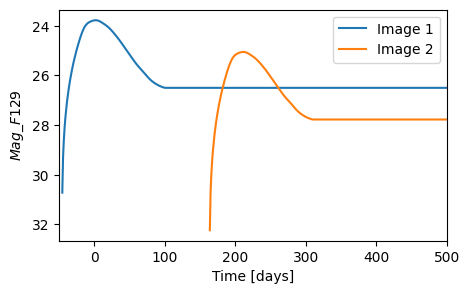

In [25]:
time = np.linspace(-50, 500, 500)
# light_curve = lens_class_test.source[0].variability_class.kwargs_model

#print("This is a type", lens_class.source[0].sn_type, "SN")
magnitude = lens_class.point_source_magnitude(band="F129", lensed=True, time=time)

plt.figure(figsize=(5, 3))
plt.plot(time, magnitude[0][0], label="Image 1")
plt.plot(time, magnitude[0][1], label="Image 2")
plt.gca().invert_yaxis()
plt.ylabel(r"$Mag\_{F129}$")
plt.xlabel("Time [days]")
plt.xlim(-50, 500)
plt.legend()

## Simulate images 

In [ ]:
time = np.array([-25, 0, 50, 80, 90, 100, 125, 150, 200, 250])
time_series_images = []
for t in time:
    image_roman = lens_image_roman(
        lens_class=lens_class,
        band="F129",
        mag_zero_point=27,
        num_pix=71,
        transform_pix2angle=np.array([[0.11, 0], [0, 0.11]]),
        detector=1,
        detector_pos=(2000, 2000),
        oversample=5,
        psf_directory=psf_directory,
        t_obs=t,
        with_source=True,
        with_deflector=True,
        ra=30,
        dec=-30,
        add_noise=True,
        seed=None,
    )
    time_series_images.append(image_roman)

In [27]:
pix_coord = point_source_coordinate_properties(
    lens_class=lens_class,
    band="F184",
    mag_zero_point=27,
    delta_pix=0.11,
    num_pix=71,
    transform_pix2angle=np.array([[0.11, 0], [0, 0.11]]),
)["image_pix"]

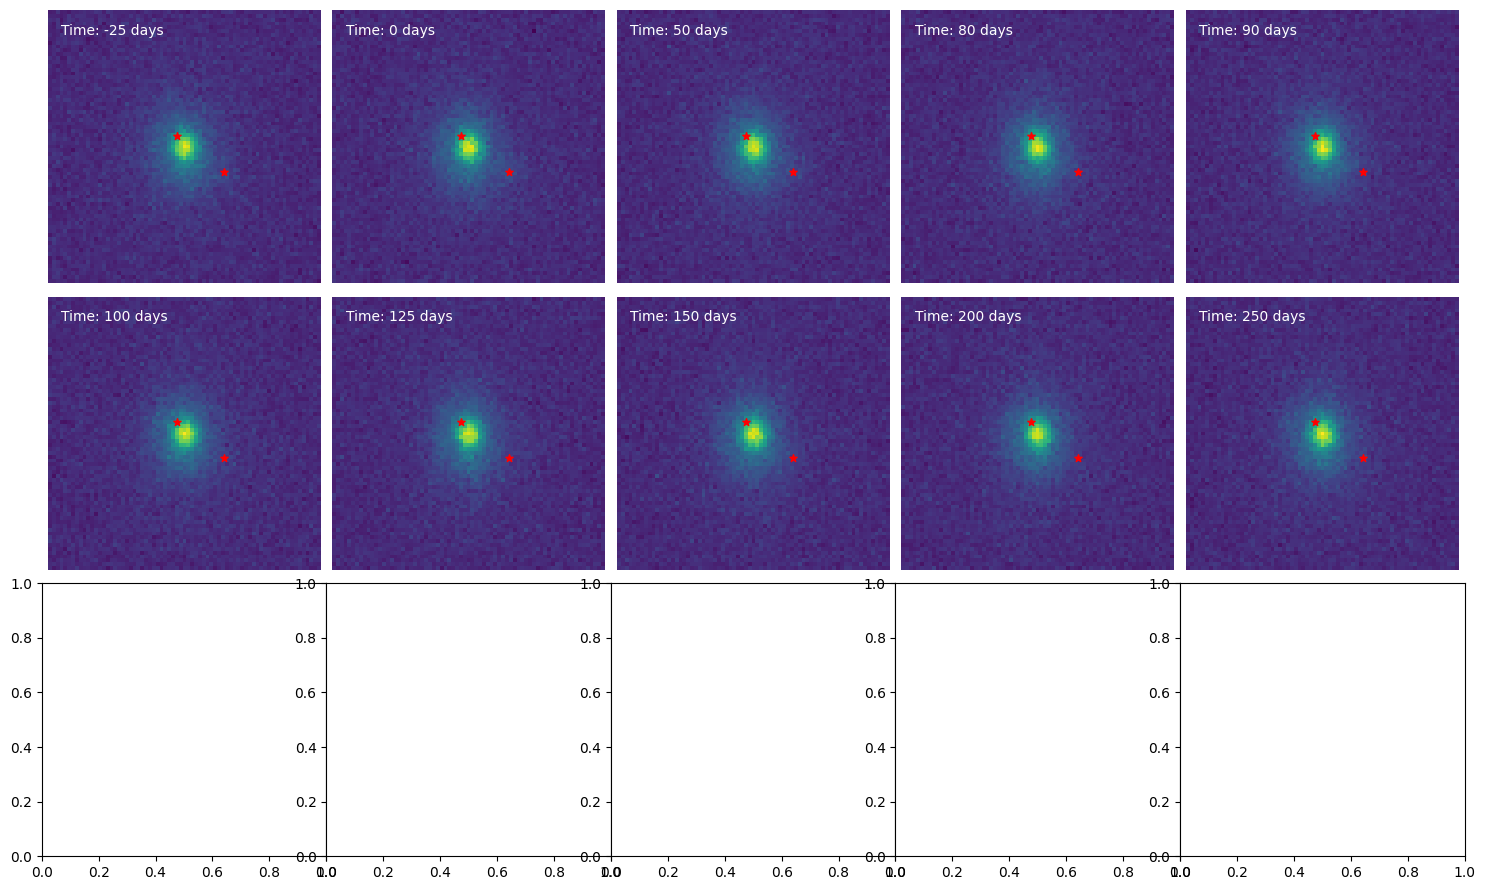

In [28]:
image_montage = create_image_montage_from_image_list(
    num_rows=3,
    num_cols=5,
    images=time_series_images,
    time=time,
    image_center=pix_coord,
)

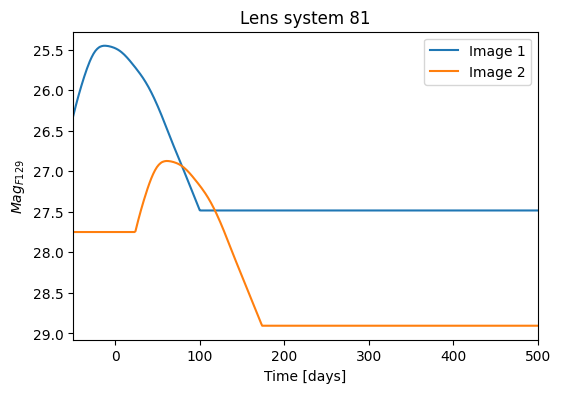

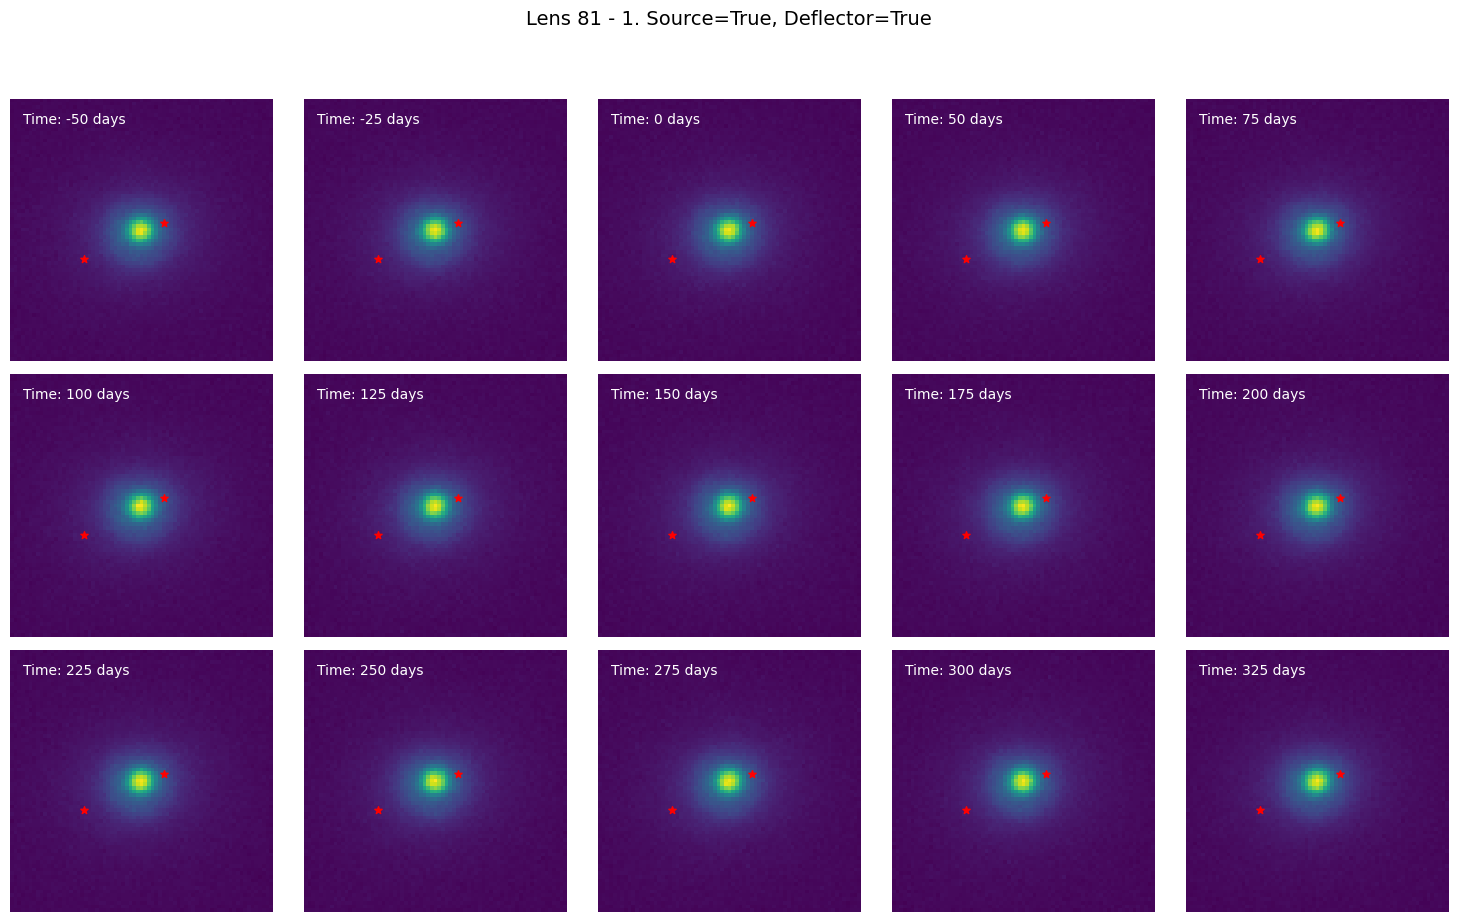

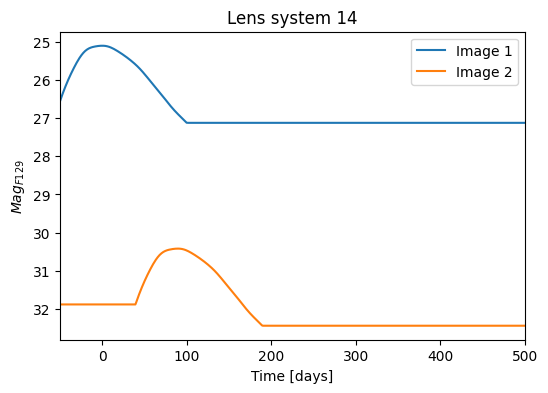

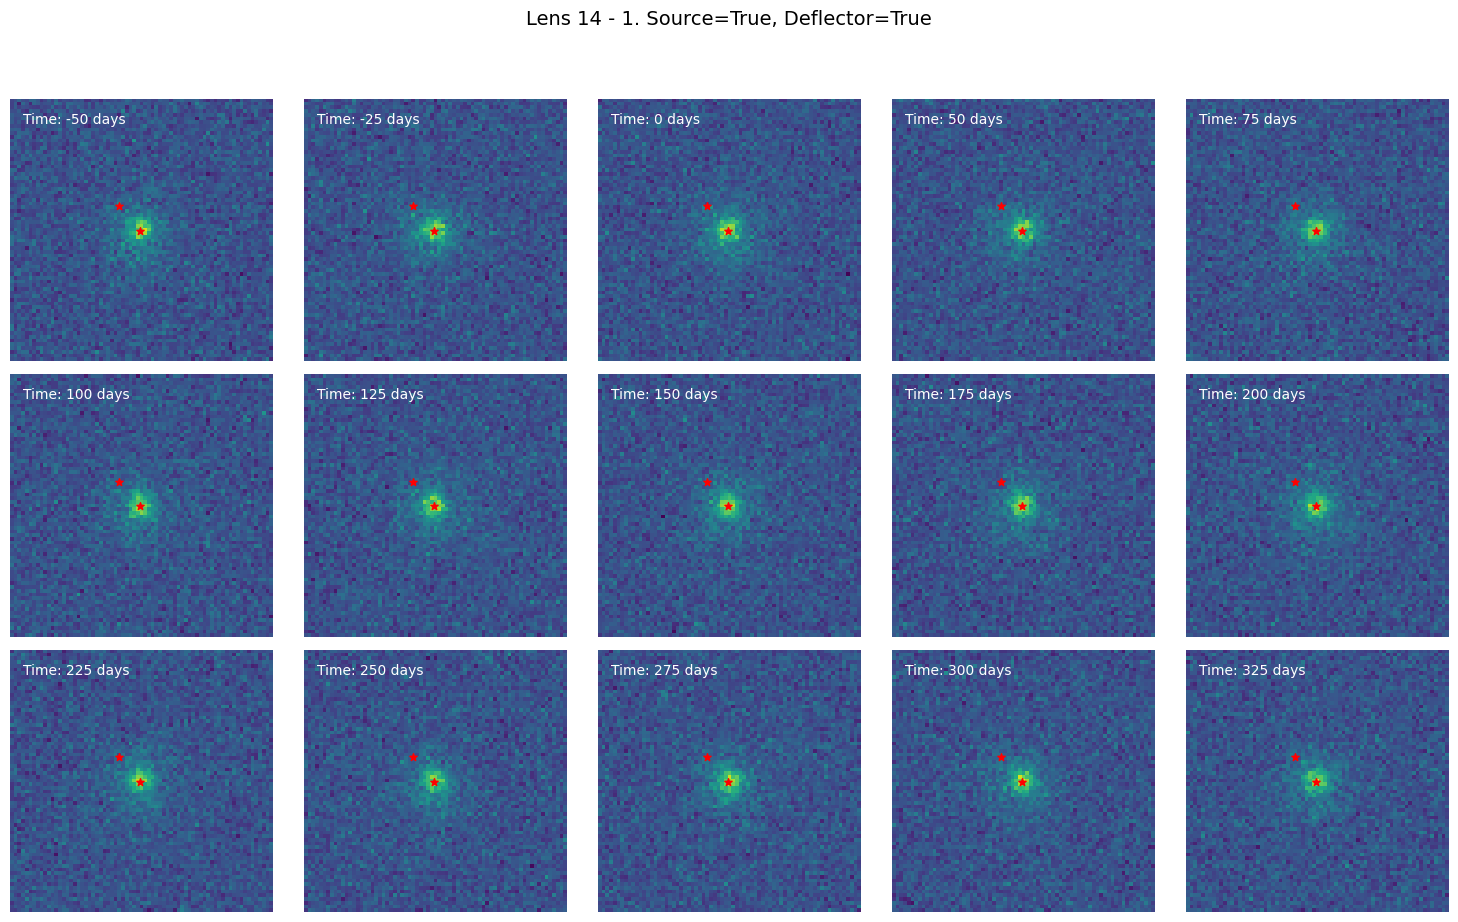

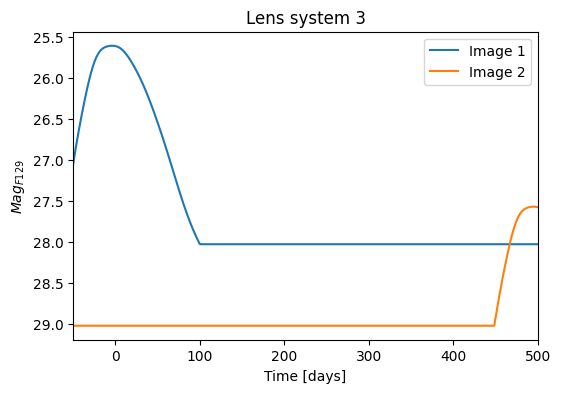

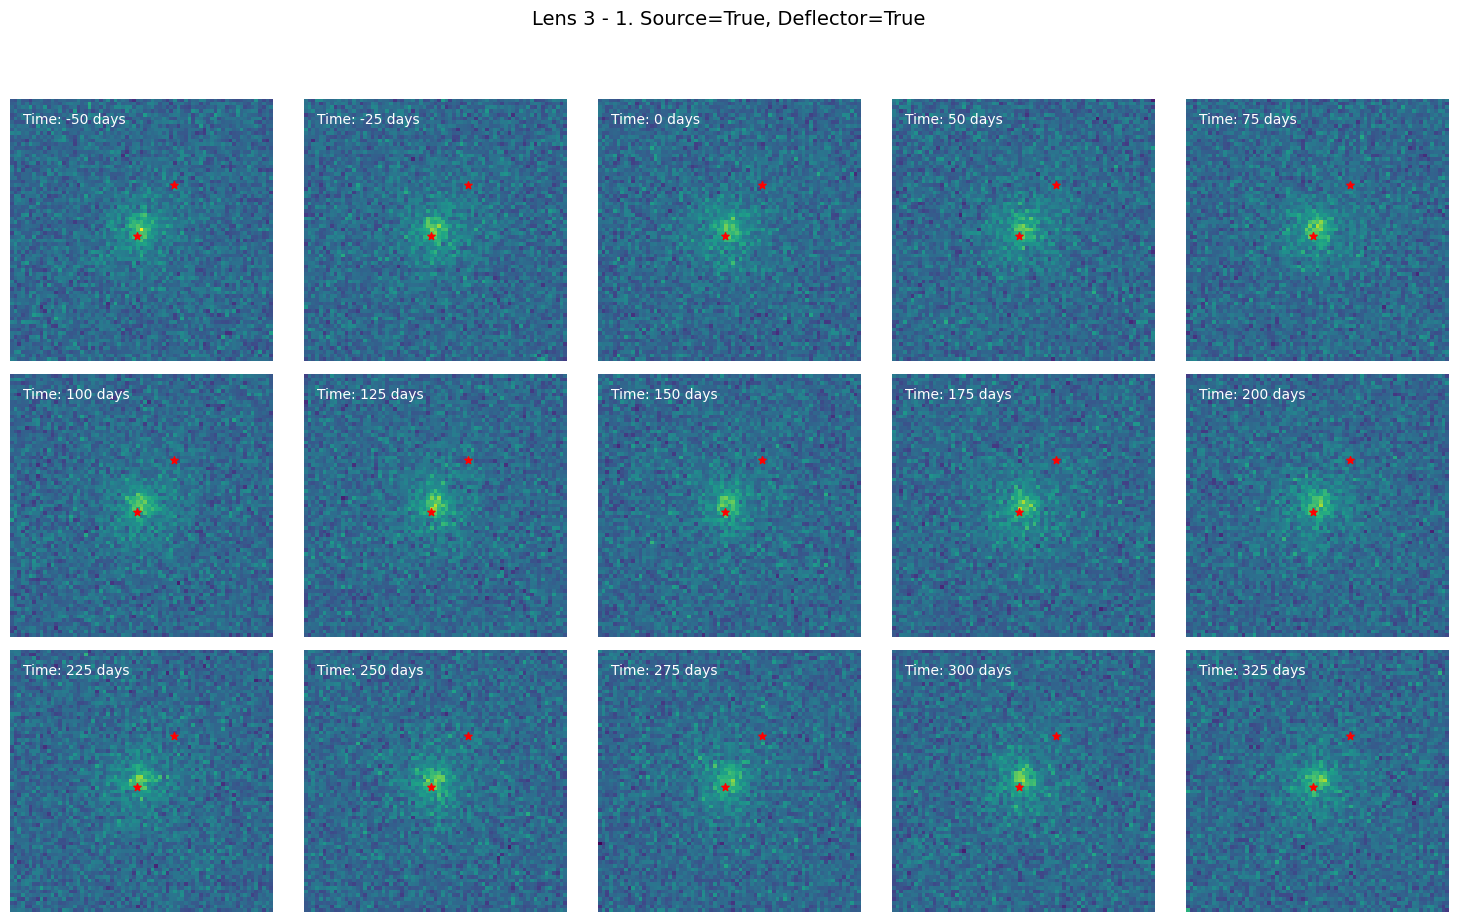

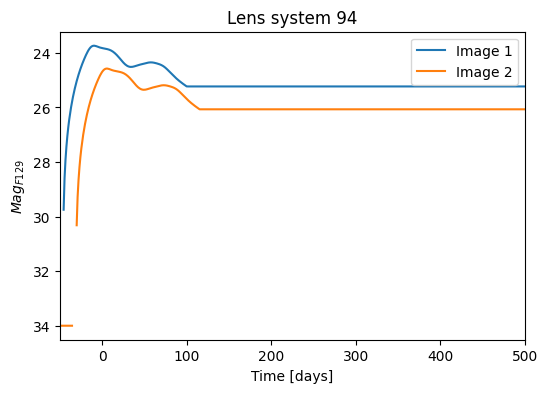

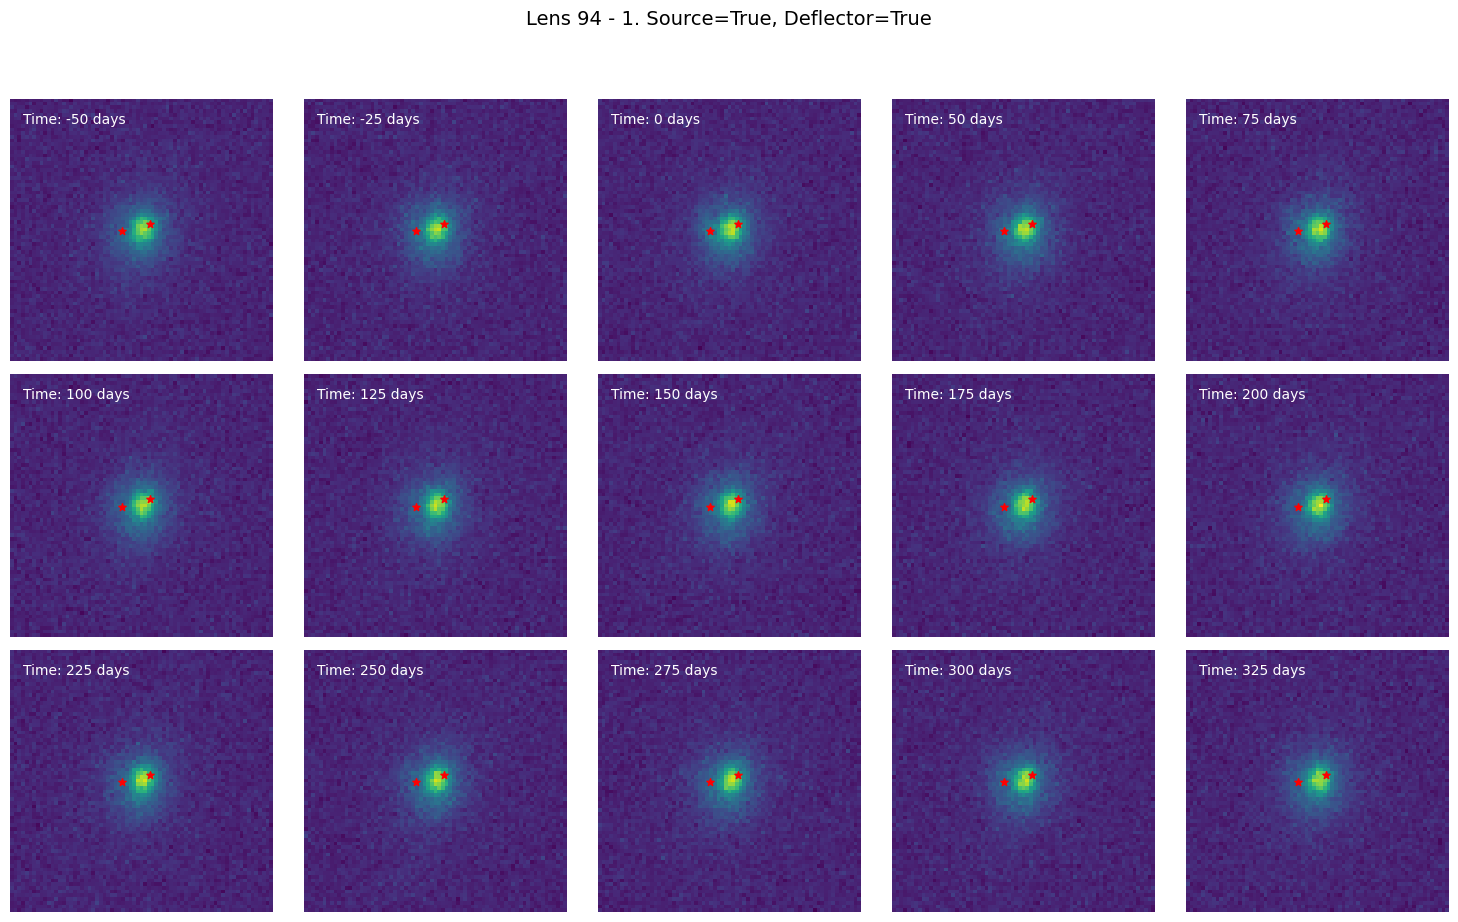

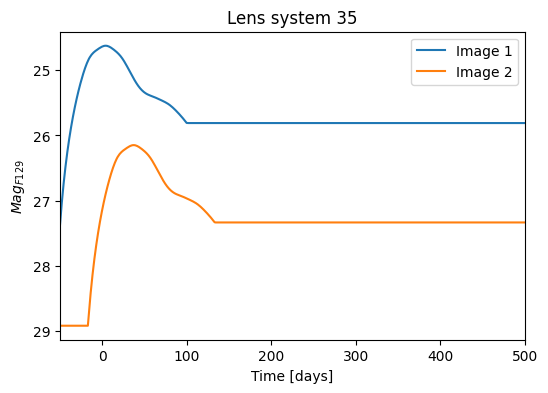

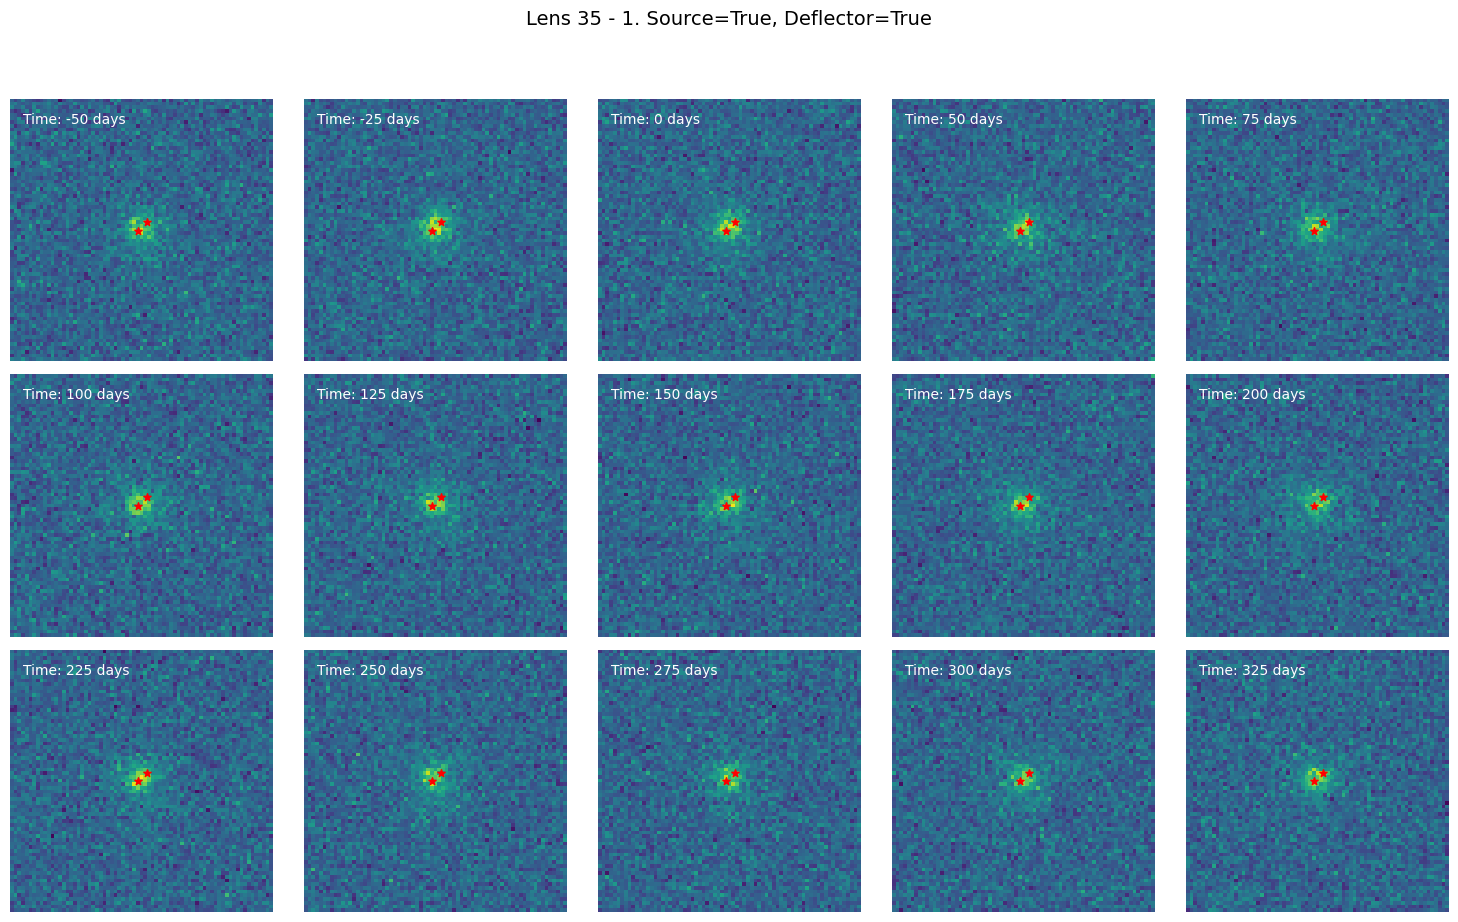

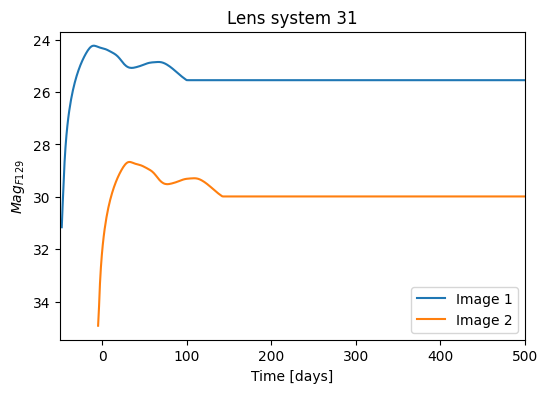

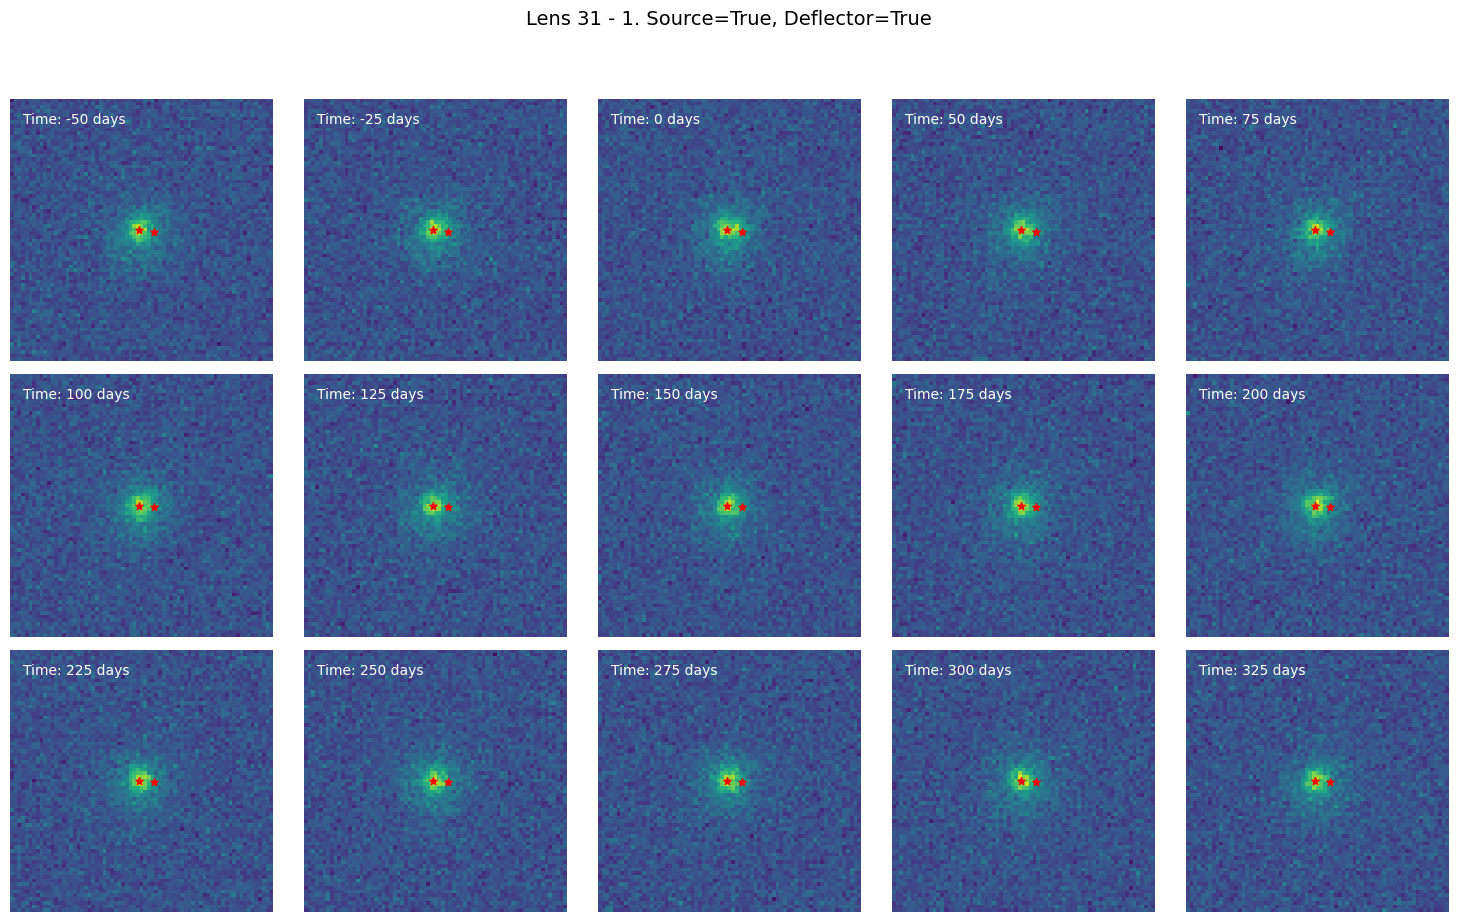

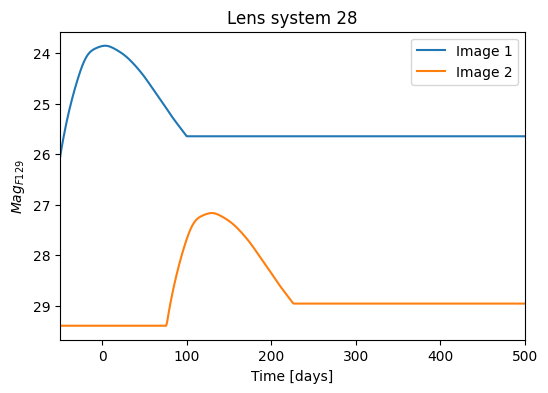

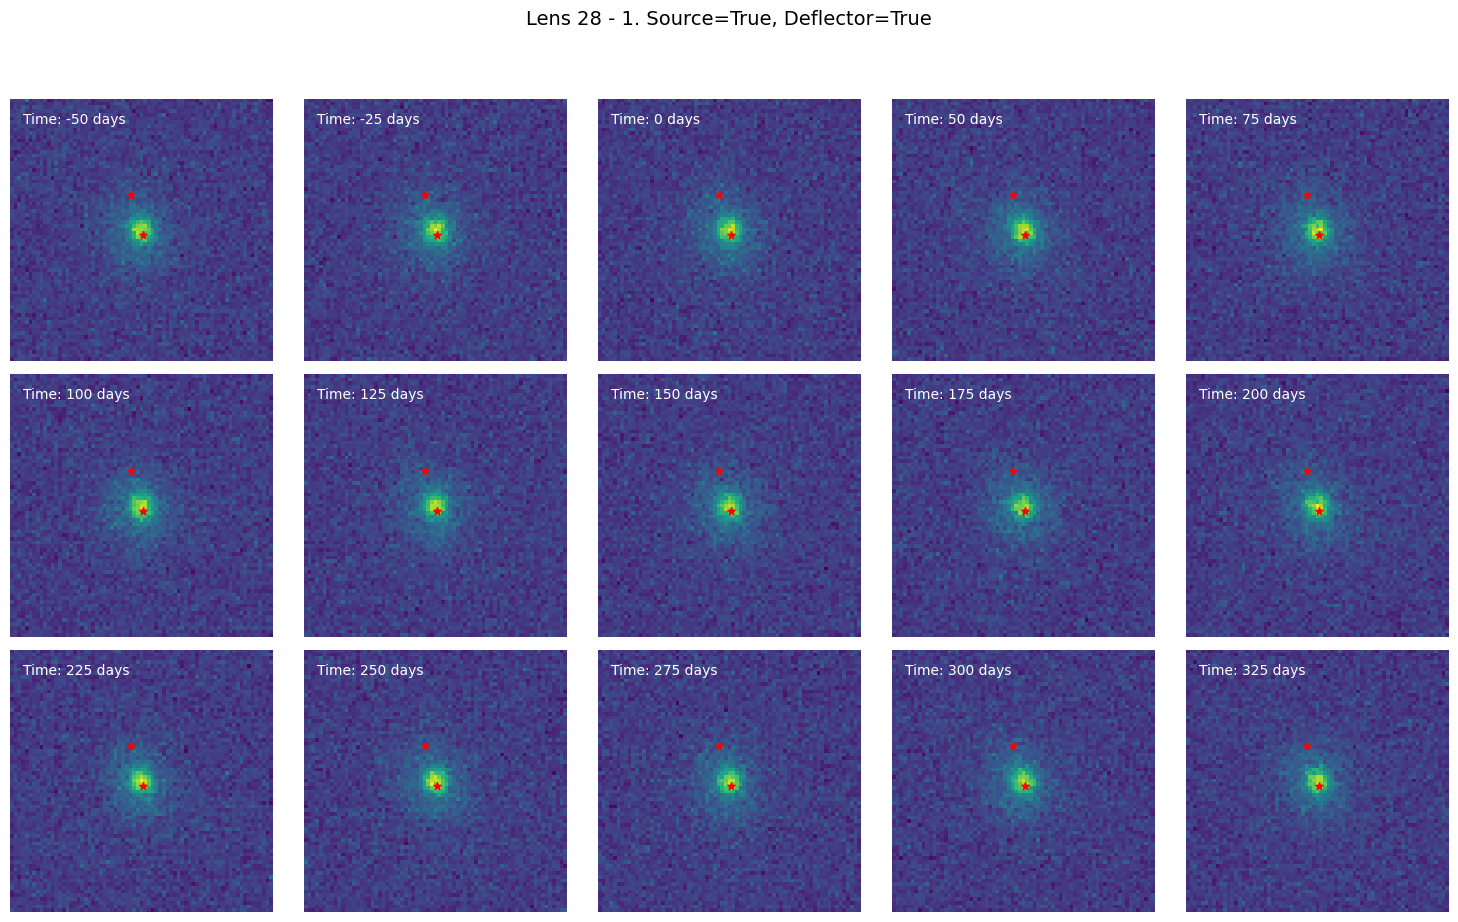

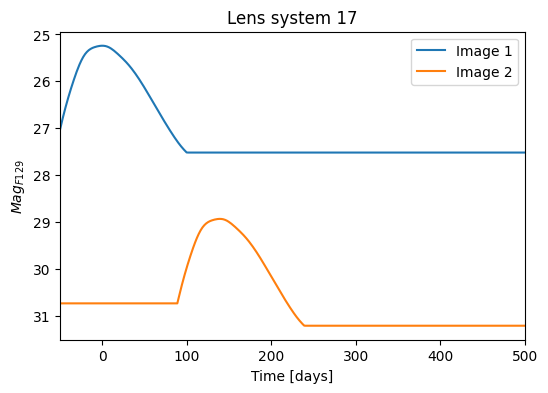

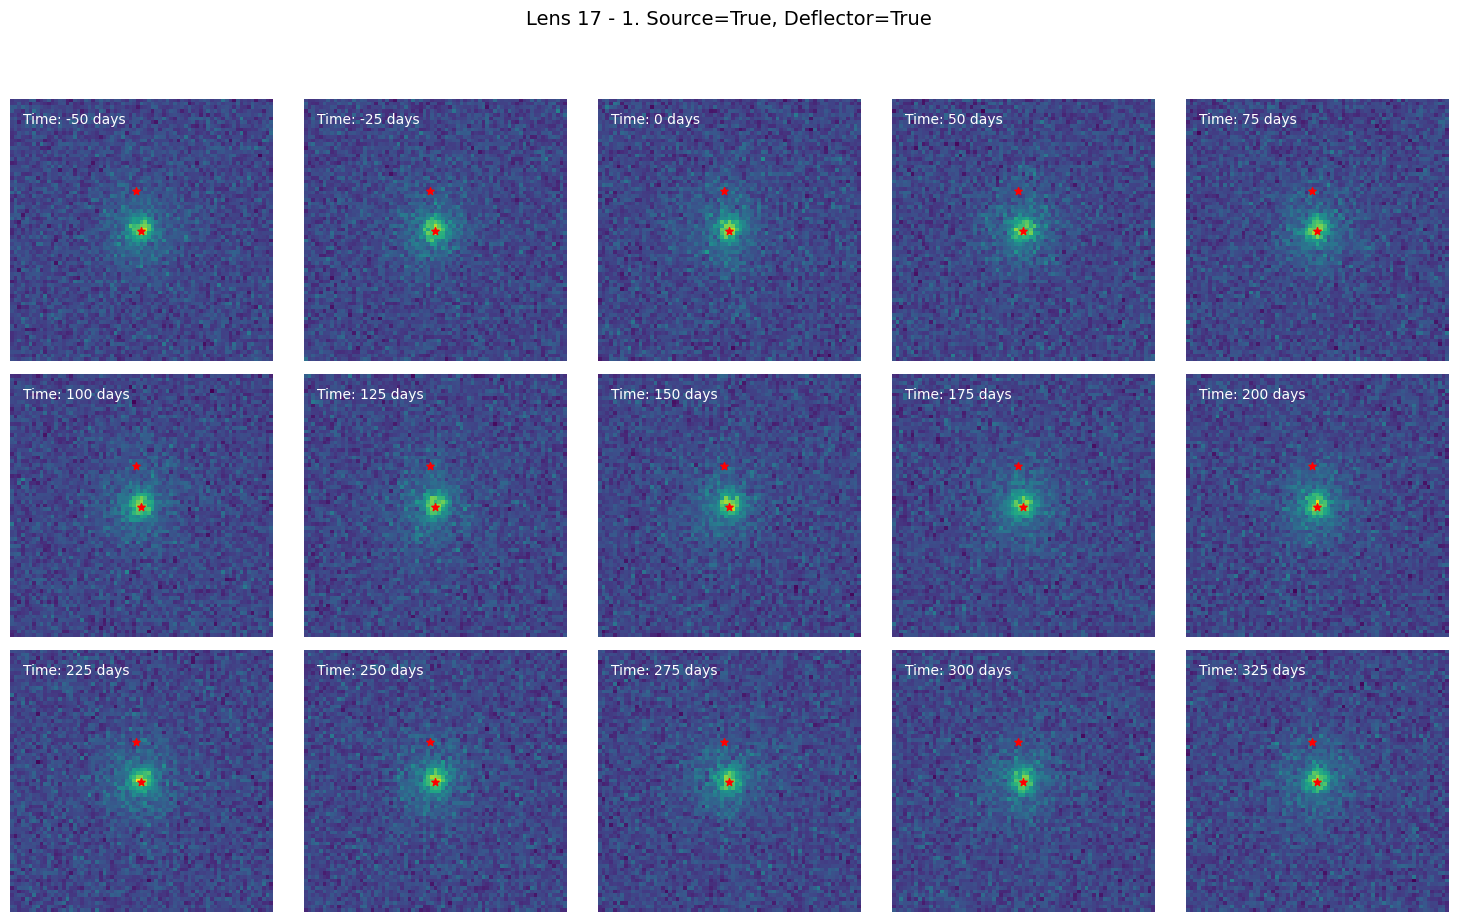

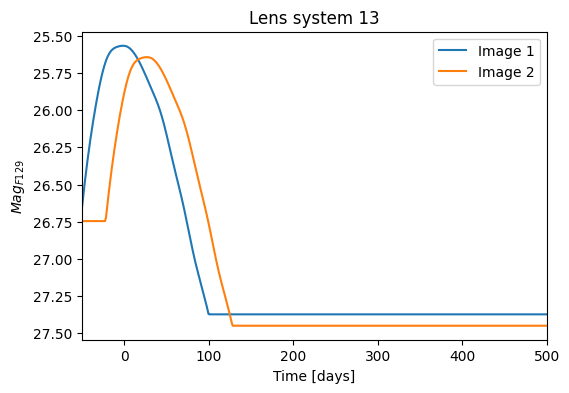

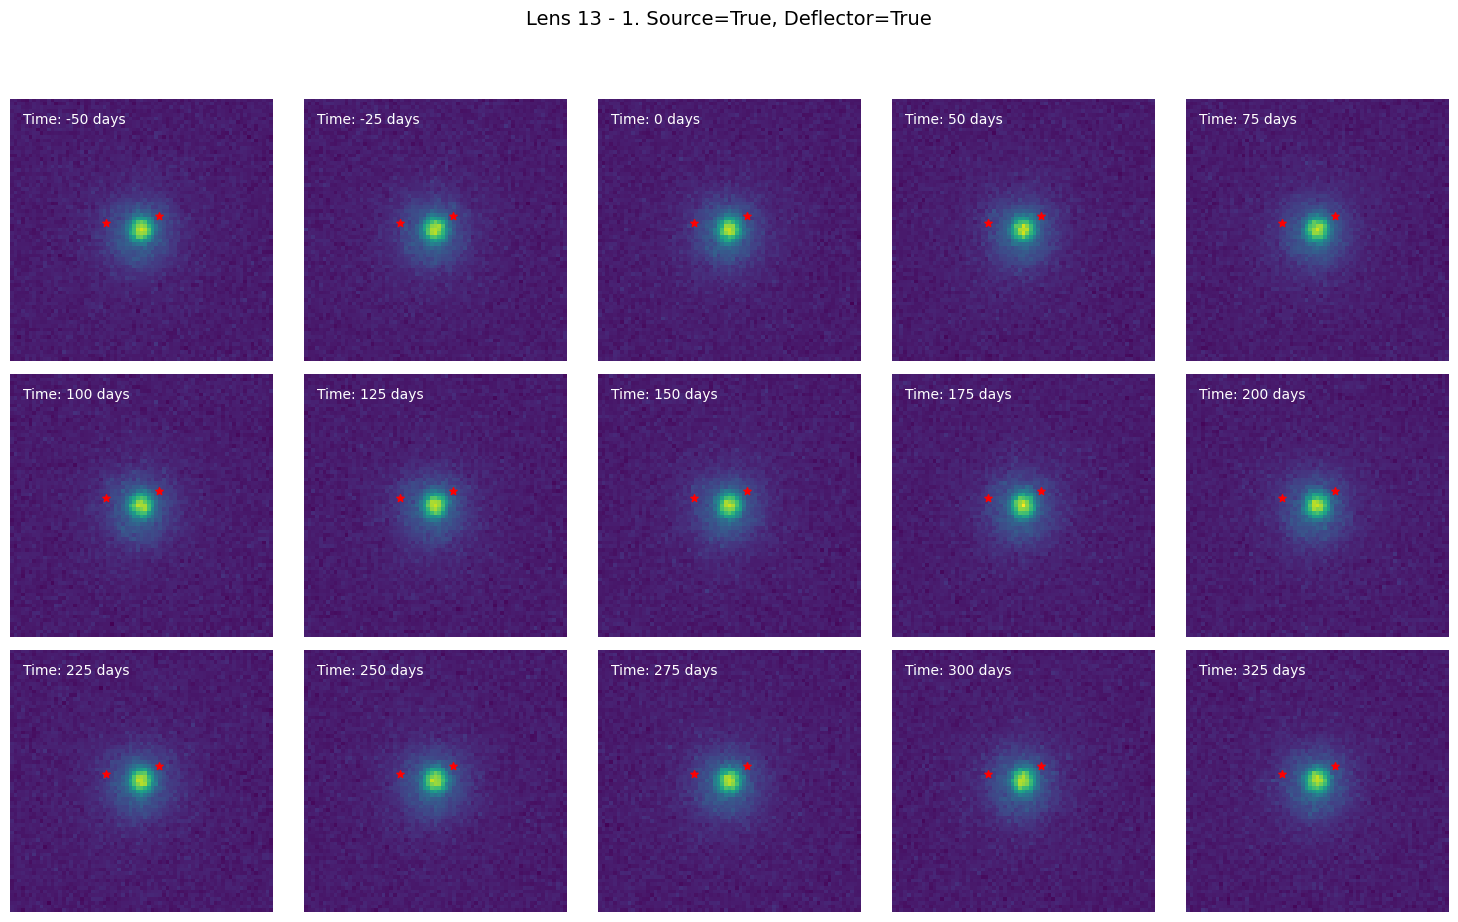

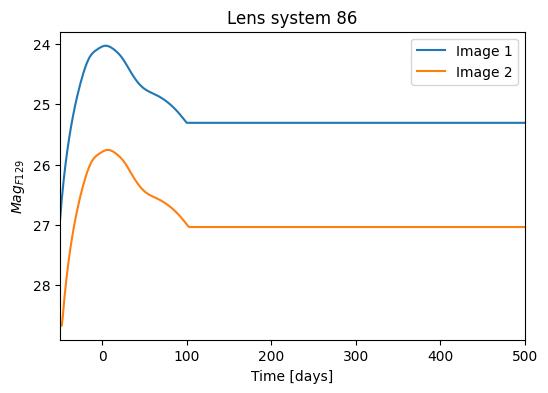

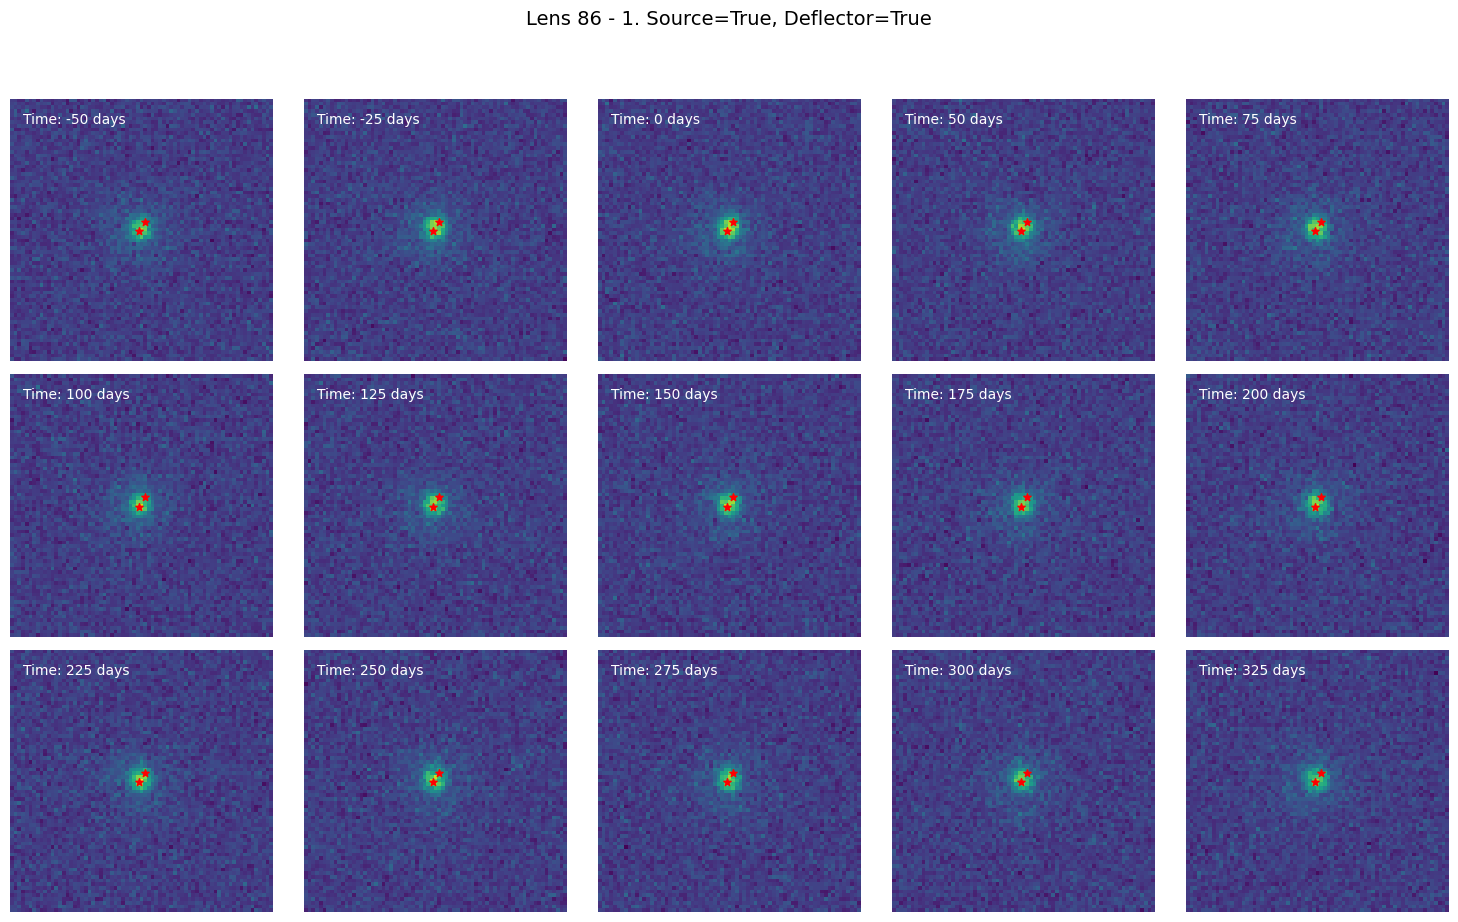

In [ ]:
import random

# Pick 10 random systems from lens_population and display their lightcurves and image montages
random.seed(42)

random_indices = random.sample(range(len(lens_population)), 10)

sample_times = np.array([-50, -25, 0, 50, 75, 
                         100, 125, 150, 175, 200, 
                         225, 250, 275, 300, 325])

def make_time_series(lens_class, with_source, with_deflector):
    """Generate list of images across time for given source/deflector flags."""
    time_series_images = []
    for t in sample_times:
        image_roman = lens_image_roman(
            lens_class=lens_class,
            band="F129",
            mag_zero_point=27,
            num_pix=71,
            transform_pix2angle=np.array([[0.11, 0], [0, 0.11]]),
            detector=1,
            detector_pos=(2000, 2000),
            oversample=5,
            psf_directory=psf_directory,
            t_obs=t,
            with_source=with_source,
            with_deflector=with_deflector,
            ra=30,
            dec=-30,
            add_noise=True,
            poisson_noise=True,
            seed=None,
        )
        time_series_images.append(image_roman)
    return time_series_images

for idx in random_indices:
    lens_class = lens_population[idx]
    
    # Light Curve
    times = np.linspace(-50, 500, 500)
    # magnitude = lens_class.point_source_magnitude(
    #     band="F062", lensed=True, time=times
    # ) #returned nans for F062

    magnitude = lens_class.point_source_magnitude(
        band="F184", lensed=True, time=times
    )

    plt.figure(figsize=(6, 4))
    for i in range(len(magnitude[0])):
        plt.plot(times, magnitude[0][i], label=f"Image {i+1}")
    plt.gca().invert_yaxis()
    plt.ylabel(r"$Mag_{F129}$")
    plt.xlabel("Time [days]")
    plt.xlim(-50, 500)
    plt.title(f"Lens system {idx}")
    plt.legend()
    plt.show()

    # Image Montages
    images_both      = make_time_series(lens_class, with_source=True,  with_deflector=True)
    # images_deflector = make_time_series(lens_class, with_source=False, with_deflector=True)
    # images_source    = make_time_series(lens_class, with_source=True, with_deflector=False)
    # images_sub       = [img_b - img_d for img_b, img_d in zip(images_both, images_deflector)]

    pix_coord = point_source_coordinate_properties(
        lens_class=lens_class,
        band="F184",
        mag_zero_point=27,
        delta_pix=0.11,
        num_pix=71,
        transform_pix2angle=np.array([[0.11, 0], [0, 0.11]]),
    )["image_pix"]

    titles = [
        "1. Source=True, Deflector=True",
        "2. Source=False, Deflector=True",
        "3. Source=True, Deflector=False",
        "4. Source Only (Both - Deflector)"
    ]
    images = [images_both]  # , images_deflector, images_source, images_sub

    for title, imgs in zip(titles, images):
        fig = create_image_montage_from_image_list(
            num_rows=3,
            num_cols=5,
            images=imgs,
            time=sample_times,
            image_center=pix_coord,
        )
        fig.suptitle(f"Lens {idx} - {title}", fontsize=14, y=1.02)
        fig.subplots_adjust(top=0.92)